# Railway Delay Prediction using a Connected Bayesian Network

This notebook implements the railway-delay Bayesian Network with the **same node set and directed connections as the supplied reference diagram**, with bounded categories to keep CPT fitting feasible.

## 1. Install dependencies

Run this cell once in the notebook environment. If `pgmpy` is already installed, you can skip it.

In [3]:
%pip install -q pandas numpy scikit-learn matplotlib networkx pgmpy joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and load the dataset

In [4]:
import os, warnings, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, log_loss
)
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
MAX_ROWS = 200_000  # Raise this if your computer has enough RAM.

CSV_PATH = r"C:\Users\Lenovo\Desktop\Sai Ganesh\Studies\B Tech\Semester 5\Probabibility Reasoning\Project\Dataset pr\dataset.csv"
# Change CSV_PATH to the location of your CSV file.
df = pd.read_csv(CSV_PATH, low_memory=False)
df.columns = (df.columns.astype(str).str.strip().str.upper()
              .str.replace(r"[^A-Z0-9]+", "_", regex=True).str.strip("_"))

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (5819079, 31)
Columns: ['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'TRAIN_OPERATOR', 'TRAIN_NUMBER', 'COACH_ID', 'SOURCE_STATION', 'DESTINATION_STATION', 'SCHEDULED_DEPARTURE', 'ACTUAL_DEPARTURE', 'DELAY_DEPARTURE', 'PLATFORM_TIME_OUT', 'TRAIN_DEPARTURE_EVENT', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'RUN_TIME', 'DISTANCE_KM', 'LEFT_SOURCE_STATION_TIME', 'PLATFORM_TIME_IN', 'SCHEDULED_ARRIVAL', 'ACTUAL_ARRIVAL', 'DELAY_ARRIVAL', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON', 'SYSTEM_DELAY', 'SECURITY_DELAY', 'TRAIN_OPERATOR_DELAY', 'LATE_TRAIN_DELAY', 'WEATHER_DELAY']


,YEAR,MONTH,DAY,DAY_OF_WEEK,TRAIN_OPERATOR,TRAIN_NUMBER,COACH_ID,SOURCE_STATION,DESTINATION_STATION,SCHEDULED_DEPARTURE,...,ACTUAL_ARRIVAL,DELAY_ARRIVAL,DIVERTED,CANCELLED,CANCELLATION_REASON,SYSTEM_DELAY,SECURITY_DELAY,TRAIN_OPERATOR_DELAY,LATE_TRAIN_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Clean fields and define the target

In [5]:
def numeric_col(data, name):
    if name in data.columns:
        return pd.to_numeric(data[name], errors="coerce")
    return pd.Series(np.nan, index=data.index, dtype=float)

def hhmm_to_minutes(series):
    def one(v):
        if pd.isna(v): return np.nan
        s = str(v).strip()
        try:
            if ":" in s:
                h, m = s.split(":")[:2]
                h, m = int(h), int(m[:2])
            else:
                x = float(s)
                if not x.is_integer(): return np.nan
                x = int(x); h, m = x // 100, x % 100
            return h*60+m if 0 <= h <= 23 and 0 <= m <= 59 else np.nan
        except Exception:
            return np.nan
    return series.map(one).astype(float)

# Prefer the provided arrival-delay field; otherwise derive from actual/scheduled arrival.
arrival = numeric_col(df, "DELAY_ARRIVAL")
if arrival.notna().sum() and (arrival.fillna(0) != 0).sum():
    df["ARRIVAL_DELAY_MIN"] = arrival
    print("Target delay source: DELAY_ARRIVAL")
elif {"ACTUAL_ARRIVAL", "SCHEDULED_ARRIVAL"}.issubset(df.columns):
    diff = hhmm_to_minutes(df["ACTUAL_ARRIVAL"]) - hhmm_to_minutes(df["SCHEDULED_ARRIVAL"])
    diff = diff.where(diff >= -720, diff + 1440)
    diff = diff.where(diff <= 720, diff - 1440)
    df["ARRIVAL_DELAY_MIN"] = diff
    print("Target delay source: actual minus scheduled arrival")
else:
    raise ValueError("Could not find usable DELAY_ARRIVAL or ACTUAL_ARRIVAL + SCHEDULED_ARRIVAL columns.")

df["ARRIVAL_DELAY_MIN"] = pd.to_numeric(df["ARRIVAL_DELAY_MIN"], errors="coerce")
df = df.dropna(subset=["ARRIVAL_DELAY_MIN"]).copy()
for c in ["CANCELLED", "DIVERTED"]:
    if c in df.columns:
        flag = df[c].astype(str).str.strip().str.upper()
        df = df[~flag.isin(["1", "1.0", "TRUE", "YES", "Y"])].copy()

# Early arrivals are grouped with on-time arrivals for this project.
df["ARRIVAL_DELAY_MIN"] = df["ARRIVAL_DELAY_MIN"].clip(lower=0)
df["DELAY_STATE"] = np.select(
    [df["ARRIVAL_DELAY_MIN"] <= 5, df["ARRIVAL_DELAY_MIN"] <= 15],
    ["ON_TIME", "MINOR"], default="MAJOR"
)
print("Usable records:", len(df))
display(pd.DataFrame({
    "count": df["DELAY_STATE"].value_counts(),
    "share_%": (df["DELAY_STATE"].value_counts(normalize=True)*100).round(2)
}))

Target delay source: DELAY_ARRIVAL
Usable records: 5714008


,count,share_%
DELAY_STATE,,
ON_TIME,4120933,72.12
MAJOR,1023498,17.91
MINOR,569577,9.97


## 4. Feature engineering (only from available dataset fields)

The network uses real dataset columns where available. The traffic node is explicitly a **historical route/time proxy**, not a live congestion measurement. The cause-of-delay columns are retained for post-hoc analysis, but excluded from the default predictive model to reduce target leakage.

In [6]:
# Feature engineering with bounded cardinality to keep CPTs tractable.
if len(df) > MAX_ROWS:
    work = df.sample(MAX_ROWS, random_state=RANDOM_STATE).copy()
else:
    work = df.copy()
work = work.reset_index(drop=True)

# Preserve exact original values for display. The Bayesian Network uses
# grouped categories for memory efficiency, but the report should show
# the real station/operator names from the dataset.
for original_col, raw_col in [
    ("SOURCE_STATION", "SOURCE_STATION_RAW"),
    ("DESTINATION_STATION", "DESTINATION_STATION_RAW"),
    ("TRAIN_OPERATOR", "TRAIN_OPERATOR_RAW"),
]:
    if original_col in work.columns:
        work[raw_col] = work[original_col].astype("string").fillna("UNKNOWN").str.strip()
    else:
        work[raw_col] = "UNKNOWN"

def getcol(name, default="UNKNOWN"):
    if name in work.columns:
        return work[name]
    return pd.Series(default, index=work.index)

def compact_categories(series, n=10):
    s = series.astype("string").fillna("UNKNOWN").str.strip().replace("", "UNKNOWN")
    keep = set(s.value_counts().head(n).index)
    return s.where(s.isin(keep), "OTHER").astype(str)

for c in ["YEAR", "MONTH", "DAY_OF_WEEK"]:
    work[c] = getcol(c).astype("string").fillna("UNKNOWN").replace("", "UNKNOWN").astype(str)

def hhmm_to_minutes(series):
    def one(v):
        if pd.isna(v): return np.nan
        s = str(v).strip()
        try:
            if ":" in s:
                parts = s.split(":")
                h, m = int(parts[0]), int(parts[1][:2])
            else:
                x = float(s)
                if not x.is_integer(): return np.nan
                x = int(x); h, m = x // 100, x % 100
            return h*60+m if 0 <= h <= 23 and 0 <= m <= 59 else np.nan
        except Exception:
            return np.nan
    return series.map(one).astype(float)

scheduled_col = "SCHEDULED_DEPARTURE" if "SCHEDULED_DEPARTURE" in work.columns else "SCHEDULED_TIME"
mins = hhmm_to_minutes(getcol(scheduled_col, np.nan))
work["TIME_PERIOD"] = pd.cut(
    mins, bins=[-1,359,719,1079,1439],
    labels=["NIGHT","MORNING","AFTERNOON","EVENING"]
).astype("string").fillna("UNKNOWN").astype(str)

# Keep common station/operator values distinct and pool rare categories.
work["SOURCE_STATION"] = compact_categories(getcol("SOURCE_STATION"), n=12)
work["DESTINATION_STATION"] = compact_categories(getcol("DESTINATION_STATION"), n=12)
work["TRAIN_OPERATOR"] = compact_categories(getcol("TRAIN_OPERATOR"), n=8)

dist = pd.to_numeric(getcol("DISTANCE_KM"), errors="coerce")
if dist.notna().sum() > 0 and dist.nunique() >= 3:
    work["DISTANCE_BAND"] = pd.qcut(
        dist, q=3, labels=["SHORT","MEDIUM","LONG"], duplicates="drop"
    ).astype("string").fillna("UNKNOWN").astype(str)
else:
    work["DISTANCE_BAND"] = "UNKNOWN"

dep = pd.to_numeric(getcol("DELAY_DEPARTURE"), errors="coerce")
if dep.notna().sum() > 0:
    work["DEPARTURE_DELAY_STATE"] = np.select(
        [dep.fillna(0) <= 5, dep.fillna(0) <= 15],
        ["ON_TIME","MINOR"], default="MAJOR"
    )
else:
    work["DEPARTURE_DELAY_STATE"] = "UNKNOWN"

date_parts = [getcol(c, "UNKNOWN").astype("string").fillna("UNKNOWN")
              for c in ["YEAR","MONTH","DAY"]]
work["_DATE_KEY"] = date_parts[0] + "-" + date_parts[1] + "-" + date_parts[2]
traffic = work.groupby(
    ["_DATE_KEY","SOURCE_STATION","TIME_PERIOD"], observed=True
)["TRAIN_NUMBER"].transform("size")
if traffic.nunique() >= 3:
    work["TRAFFIC_LEVEL"] = pd.qcut(
        traffic.rank(method="first"), q=3, labels=["LOW","MEDIUM","HIGH"]
    ).astype("string").astype(str)
else:
    work["TRAFFIC_LEVEL"] = np.where(traffic <= traffic.median(), "LOW", "HIGH")

# Delay-cause nodes are derived only when corresponding dataset columns exist.
# States: NONE, LOW, HIGH, UNKNOWN. These are descriptive historical fields.
cause_map = {
    "WEATHER_CAUSE_STATE": "WEATHER_DELAY",
    "SYSTEM_CAUSE_STATE": "SYSTEM_DELAY",
    "SECURITY_CAUSE_STATE": "SECURITY_DELAY",
    "OPERATOR_CAUSE_STATE": "TRAIN_OPERATOR_DELAY",
    "LATE_TRAIN_CAUSE_STATE": "LATE_TRAIN_DELAY",
}
for new_col, raw_col in cause_map.items():
    if raw_col in work.columns:
        values = pd.to_numeric(work[raw_col], errors="coerce")
        work[new_col] = np.select(
            [values.isna(), values.fillna(0) <= 0, values.fillna(0) <= 30],
            ["UNKNOWN", "NONE", "LOW"], default="HIGH"
        )
    else:
        work[new_col] = "UNKNOWN"

# Compact summary of recorded causes. Five categorical inputs -> at most 4^5
# combinations, but the summary node itself has only a small number of states.
cause_cols = list(cause_map.keys())
cause_count = sum((work[c] != "NONE") & (work[c] != "UNKNOWN") for c in cause_cols)
work["DELAY_CAUSE_PROFILE"] = np.select(
    [cause_count == 0, cause_count == 1, cause_count >= 2],
    ["NO_RECORDED_CAUSE", "ONE_RECORDED_CAUSE", "MULTIPLE_RECORDED_CAUSES"],
    default="UNKNOWN"
)

print("Sample used:", len(work), "rows")
print("Node cardinalities:")
for c in ["YEAR","MONTH","DAY_OF_WEEK","TIME_PERIOD","SOURCE_STATION",
          "DESTINATION_STATION","DISTANCE_BAND","TRAIN_OPERATOR",
          "TRAFFIC_LEVEL","DEPARTURE_DELAY_STATE"] + cause_cols + ["DELAY_CAUSE_PROFILE"]:
    print(f"{c}: {work[c].nunique()} states")
print("Target distribution:")
display(work["DELAY_STATE"].value_counts().rename_axis("DELAY_STATE").to_frame("records"))

Sample used: 200000 rows
Node cardinalities:
YEAR: 1 states
MONTH: 12 states
DAY_OF_WEEK: 7 states
TIME_PERIOD: 4 states
SOURCE_STATION: 13 states
DESTINATION_STATION: 13 states
DISTANCE_BAND: 3 states
TRAIN_OPERATOR: 9 states
TRAFFIC_LEVEL: 3 states
DEPARTURE_DELAY_STATE: 3 states
WEATHER_CAUSE_STATE: 4 states
SYSTEM_CAUSE_STATE: 4 states
SECURITY_CAUSE_STATE: 4 states
OPERATOR_CAUSE_STATE: 4 states
LATE_TRAIN_CAUSE_STATE: 4 states
DELAY_CAUSE_PROFILE: 3 states
Target distribution:


,records
DELAY_STATE,
ON_TIME,144367
MAJOR,35643
MINOR,19990


## 5. Enhanced Bayesian Network structure

This is a richer but still interpretable structure. It includes **calendar → time context**, **route + time → traffic proxy**, **operator / route / traffic / departure state → arrival-delay state**. The model deliberately does not include `WEATHER_DELAY`, `SYSTEM_DELAY`, `SECURITY_DELAY`, `TRAIN_OPERATOR_DELAY`, or `LATE_TRAIN_DELAY` as default predictors: these are often recorded as explanations after an incident and can leak information about the target.

In [7]:
# Bayesian Network topology matched to the user's reference diagram.
# Every node is connected; the graph is directed and acyclic.
bn_columns = [
    "YEAR", "MONTH", "DAY_OF_WEEK", "TIME_PERIOD",
    "SOURCE_STATION", "DESTINATION_STATION", "DISTANCE_BAND",
    "TRAIN_OPERATOR", "TRAFFIC_LEVEL", "DEPARTURE_DELAY_STATE",
    "WEATHER_CAUSE_STATE", "SYSTEM_CAUSE_STATE", "SECURITY_CAUSE_STATE",
    "OPERATOR_CAUSE_STATE", "LATE_TRAIN_CAUSE_STATE",
    "DELAY_CAUSE_PROFILE", "DELAY_STATE"
]
bn_data = work[bn_columns].copy()
for c in bn_columns:
    bn_data[c] = bn_data[c].astype("string").fillna("UNKNOWN").astype(str)

# Same node-to-node connections as the reference image.
edges = [
    ("YEAR", "MONTH"),
    ("MONTH", "DAY_OF_WEEK"),
    ("DAY_OF_WEEK", "TIME_PERIOD"),

    ("SOURCE_STATION", "DESTINATION_STATION"),
    ("DESTINATION_STATION", "DISTANCE_BAND"),
    ("SOURCE_STATION", "TRAFFIC_LEVEL"),
    ("TIME_PERIOD", "TRAFFIC_LEVEL"),
    ("DISTANCE_BAND", "DEPARTURE_DELAY_STATE"),
    ("TRAFFIC_LEVEL", "DEPARTURE_DELAY_STATE"),
    ("TRAIN_OPERATOR", "DEPARTURE_DELAY_STATE"),

    ("WEATHER_CAUSE_STATE", "DELAY_CAUSE_PROFILE"),
    ("SYSTEM_CAUSE_STATE", "DELAY_CAUSE_PROFILE"),
    ("SECURITY_CAUSE_STATE", "DELAY_CAUSE_PROFILE"),
    ("OPERATOR_CAUSE_STATE", "DELAY_CAUSE_PROFILE"),
    ("LATE_TRAIN_CAUSE_STATE", "DELAY_CAUSE_PROFILE"),

    ("TIME_PERIOD", "DELAY_STATE"),
    ("DEPARTURE_DELAY_STATE", "DELAY_STATE"),
    ("DELAY_CAUSE_PROFILE", "DELAY_STATE")
]
model = DiscreteBayesianNetwork(edges)

train_idx, test_idx = train_test_split(
    np.arange(len(bn_data)), test_size=0.20, random_state=RANDOM_STATE,
    stratify=bn_data["DELAY_STATE"]
)
train_data = bn_data.iloc[train_idx].copy()
test_data = bn_data.iloc[test_idx].copy()

G_check = nx.DiGraph(edges)
assert set(G_check.nodes()) == set(bn_columns), "Some nodes are missing from the graph."
assert nx.is_weakly_connected(G_check), "Graph must be connected."
assert nx.is_directed_acyclic_graph(G_check), "Bayesian Network must be acyclic."

state_counts = {c: int(train_data[c].nunique()) for c in bn_columns}
print("CPT size estimates:")
for node in model.nodes():
    parents = list(model.predecessors(node))
    combinations = int(np.prod([state_counts[p] for p in parents])) if parents else 1
    cells = combinations * state_counts[node]
    print(f"{node}: parents={parents}, approx. CPT cells={cells:,}")

estimator = BayesianEstimator(model, train_data)
model.add_cpds(*estimator.get_parameters(
    prior_type="BDeu", equivalent_sample_size=10, n_jobs=1
))
assert model.check_model()
print(f"Trained: {len(model.nodes())} nodes, {len(model.edges())} directed edges")
print("Connected:", nx.is_weakly_connected(G_check))
print("Acyclic:", nx.is_directed_acyclic_graph(G_check))

CPT size estimates:
YEAR: parents=[], approx. CPT cells=1
MONTH: parents=['YEAR'], approx. CPT cells=12
DAY_OF_WEEK: parents=['MONTH'], approx. CPT cells=84
TIME_PERIOD: parents=['DAY_OF_WEEK'], approx. CPT cells=28
SOURCE_STATION: parents=[], approx. CPT cells=13
DESTINATION_STATION: parents=['SOURCE_STATION'], approx. CPT cells=169
DISTANCE_BAND: parents=['DESTINATION_STATION'], approx. CPT cells=39
TRAFFIC_LEVEL: parents=['SOURCE_STATION', 'TIME_PERIOD'], approx. CPT cells=156
DEPARTURE_DELAY_STATE: parents=['DISTANCE_BAND', 'TRAFFIC_LEVEL', 'TRAIN_OPERATOR'], approx. CPT cells=243
TRAIN_OPERATOR: parents=[], approx. CPT cells=9
WEATHER_CAUSE_STATE: parents=[], approx. CPT cells=4
DELAY_CAUSE_PROFILE: parents=['WEATHER_CAUSE_STATE', 'SYSTEM_CAUSE_STATE', 'SECURITY_CAUSE_STATE', 'OPERATOR_CAUSE_STATE', 'LATE_TRAIN_CAUSE_STATE'], approx. CPT cells=3,072
SYSTEM_CAUSE_STATE: parents=[], approx. CPT cells=4
SECURITY_CAUSE_STATE: parents=[], approx. CPT cells=4
OPERATOR_CAUSE_STATE: paren

## 6. Visualize the improved network

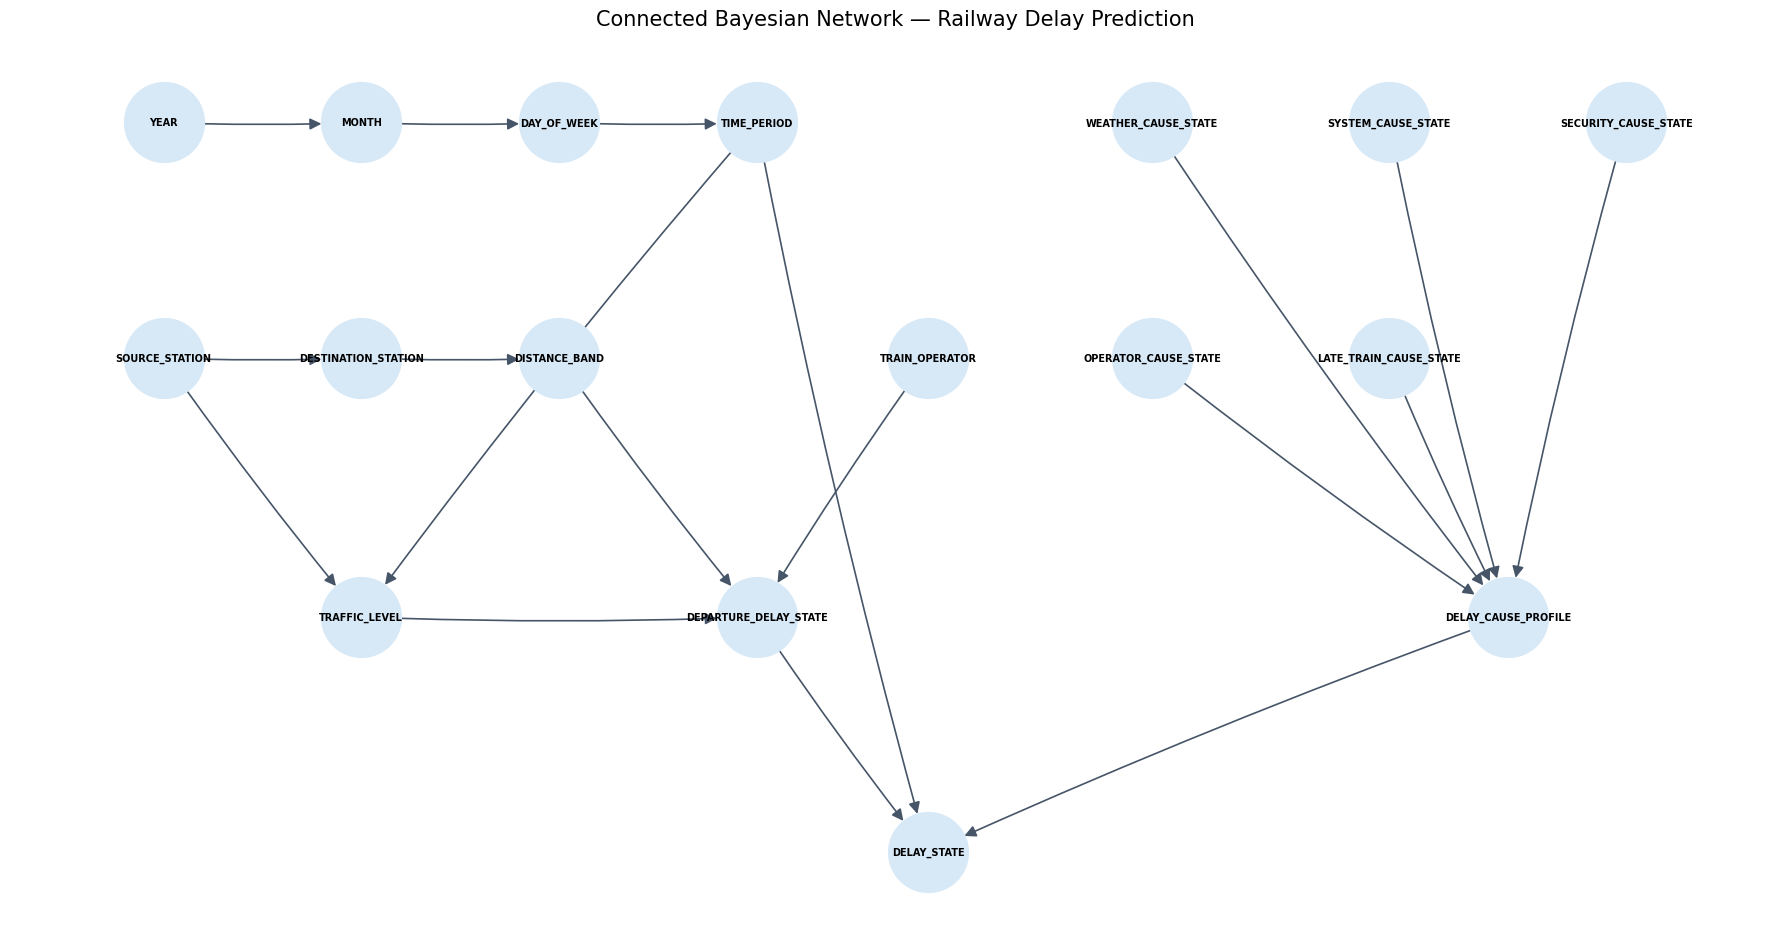

In [8]:
# Layout closely matches the supplied reference image.
G = nx.DiGraph()
G.add_edges_from(edges)

pos = {
    "YEAR": (-5.5, 3.2),
    "MONTH": (-4.0, 3.2),
    "DAY_OF_WEEK": (-2.5, 3.2),
    "TIME_PERIOD": (-1.0, 3.2),

    "SOURCE_STATION": (-5.5, 1.2),
    "DESTINATION_STATION": (-4.0, 1.2),
    "DISTANCE_BAND": (-2.5, 1.2),
    "TRAFFIC_LEVEL": (-4.0, -1.0),
    "DEPARTURE_DELAY_STATE": (-1.0, -1.0),
    "TRAIN_OPERATOR": (0.3, 1.2),

    "WEATHER_CAUSE_STATE": (2.0, 3.2),
    "SYSTEM_CAUSE_STATE": (3.8, 3.2),
    "SECURITY_CAUSE_STATE": (5.6, 3.2),
    "OPERATOR_CAUSE_STATE": (2.0, 1.2),
    "LATE_TRAIN_CAUSE_STATE": (3.8, 1.2),
    "DELAY_CAUSE_PROFILE": (4.7, -1.0),
    "DELAY_STATE": (0.3, -3.0)
}

plt.figure(figsize=(18, 9.5))
nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,
    node_size=3300,
    node_color="#d7e9f7",
    edge_color="#465568",
    font_size=7,
    font_weight="bold",
    arrows=True,
    arrowsize=17,
    width=1.2,
    connectionstyle="arc3,rad=0.02"
)
plt.title("Connected Bayesian Network — Railway Delay Prediction", fontsize=15, pad=15)
plt.axis("off")
plt.tight_layout()
os.makedirs("railway_bn_results", exist_ok=True)
plt.savefig("railway_bn_results/enhanced_bayesian_network.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Inference and model evaluation

Evaluated records: 500
Accuracy: 83.60%
Balanced accuracy: 58.89%

Classification report:
              precision    recall  f1-score   support

     ON_TIME       0.86      0.99      0.92       359
       MINOR       0.00      0.00      0.00        59
       MAJOR       0.72      0.78      0.75        82

    accuracy                           0.84       500
   macro avg       0.53      0.59      0.56       500
weighted avg       0.74      0.84      0.78       500



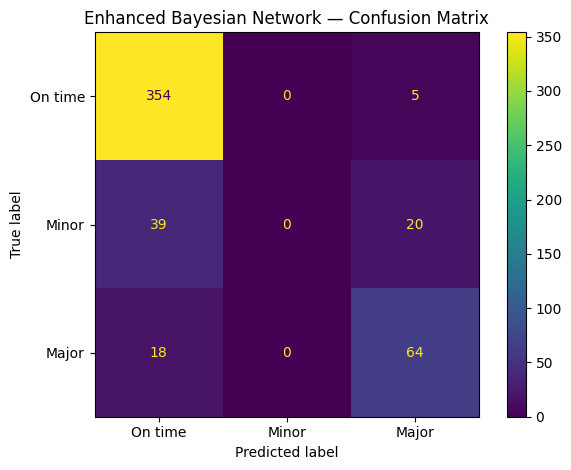

In [9]:
inference = VariableElimination(model)
# Exclude post-event cause fields from prediction evidence to reduce leakage.
evidence_columns = [
    "YEAR", "MONTH", "DAY_OF_WEEK", "TIME_PERIOD",
    "SOURCE_STATION", "DESTINATION_STATION", "DISTANCE_BAND",
    "TRAIN_OPERATOR", "TRAFFIC_LEVEL", "DEPARTURE_DELAY_STATE"
]

def predict_probabilities(row):
    evidence = {c: str(row[c]) for c in evidence_columns}
    # Unknown/unseen states can make exact inference fail. Remove evidence
    # that is not represented in the learned CPD, then retry.
    for c in list(evidence):
        try:
            states = model.get_cpds(c).state_names[c]
            if evidence[c] not in states:
                evidence.pop(c)
        except Exception:
            evidence.pop(c, None)
    q = inference.query(variables=["DELAY_STATE"], evidence=evidence, show_progress=False)
    return {s: float(p) for s, p in zip(q.state_names["DELAY_STATE"], q.values.flatten())}

EVAL_ROWS = min(500, len(test_data))
eval_df = test_data.sample(EVAL_ROWS, random_state=RANDOM_STATE)
y_true, y_pred, y_prob = [], [], []
for _, row in eval_df.iterrows():
    try:
        probs = predict_probabilities(row)
        y_true.append(row["DELAY_STATE"])
        pred = max(probs, key=probs.get)
        y_pred.append(pred)
        y_prob.append([probs.get(s, 0.0) for s in ["ON_TIME","MINOR","MAJOR"]])
    except Exception as e:
        print("Skipped row due to inference issue:", str(e)[:120])

labels = ["ON_TIME","MINOR","MAJOR"]
print("Evaluated records:", len(y_true))
if y_true:
    print(f"Accuracy: {accuracy_score(y_true,y_pred)*100:.2f}%")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_true,y_pred)*100:.2f}%")
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, labels=labels, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=["On time","Minor","Major"]).plot(values_format="d")
    plt.title("Enhanced Bayesian Network — Confusion Matrix")
    plt.tight_layout()
    plt.show()

## 8. Inspect learned conditional probability tables (CPTs)

In [10]:
for node in model.nodes():
    print("\n" + "="*80)
    print("NODE:", node)
    print(model.get_cpds(node))


NODE: YEAR
+------------+---+
| YEAR(2015) | 1 |
+------------+---+

NODE: MONTH
+-----------+---------------------+
| YEAR      | YEAR(2015)          |
+-----------+---------------------+
| MONTH(1)  | 0.08001895714851154 |
+-----------+---------------------+
| MONTH(10) | 0.08431243880590795 |
+-----------+---------------------+
| MONTH(11) | 0.08058142199445867 |
+-----------+---------------------+
| MONTH(12) | 0.082843780597046   |
+-----------+---------------------+
| MONTH(2)  | 0.07083203133137511 |
+-----------+---------------------+
| MONTH(3)  | 0.08622481928212819 |
+-----------+---------------------+
| MONTH(4)  | 0.0831875091140137  |
+-----------+---------------------+
| MONTH(5)  | 0.08635606107951585 |
+-----------+---------------------+
| MONTH(6)  | 0.08614982396933524 |
+-----------+---------------------+
| MONTH(7)  | 0.09005582984396807 |
+-----------+---------------------+
| MONTH(8)  | 0.08823719350873903 |
+-----------+---------------------+
| MONTH(9)  | 0.08

## 9. Train-number lookup and readable prediction report

The report uses the latest historical record for the selected train number within the loaded/sample data. If `MAX_ROWS` is smaller than the full dataset, a train may be absent from the sample; increase `MAX_ROWS` or implement a separate full-data lookup for that use case. This is a historical estimate, not a live operational prediction.

In [11]:
def normalize_train_number(x):
    s = str(x).strip()
    try:
        f = float(s)
        if f.is_integer(): return str(int(f))
    except Exception:
        pass
    return s.upper()

work["_TRAIN_KEY"] = work["TRAIN_NUMBER"].map(normalize_train_number)

# Mean delay by class from training records, for expected-delay approximation.
delay_ref = work.iloc[train_idx][["ARRIVAL_DELAY_MIN","DELAY_STATE"]].copy()
mean_delay_by_state = delay_ref.groupby("DELAY_STATE")["ARRIVAL_DELAY_MIN"].mean().to_dict()

def predict_train(train_number):
    key = normalize_train_number(train_number)
    matches = work[work["_TRAIN_KEY"] == key].copy()
    if matches.empty:
        print(f"No train number {train_number!r} found in the loaded sample.")
        print("Try increasing MAX_ROWS or verify the train number.")
        return None

    sort_cols = []
    for c in ["YEAR","MONTH","DAY"]:
        if c in matches.columns:
            sc = "_SORT_" + c
            matches[sc] = pd.to_numeric(matches[c], errors="coerce")
            sort_cols.append(sc)
    if sort_cols:
        matches = matches.sort_values(sort_cols, ascending=False, na_position="last")
    selected = matches.iloc[0]
    row = bn_data.loc[selected.name]
    probs = predict_probabilities(row)
    predicted = max(probs, key=probs.get)
    expected = sum(probs.get(s,0)*mean_delay_by_state.get(s,0) for s in probs)

    print("\n" + "="*60)
    print("       RAILWAY DELAY PROBABILITY REPORT")
    print("="*60)
    print("Train number:", train_number)
    source_name = selected.get("SOURCE_STATION_RAW", selected.get("SOURCE_STATION", "N/A"))
    destination_name = selected.get("DESTINATION_STATION_RAW", selected.get("DESTINATION_STATION", "N/A"))
    # If the original station fields are genuinely missing/blank, show that
    # explicitly instead of silently displaying OTHER.
    if pd.isna(source_name) or str(source_name).strip() == "":
        source_name = "UNKNOWN (missing in dataset)"
    if pd.isna(destination_name) or str(destination_name).strip() == "":
        destination_name = "UNKNOWN (missing in dataset)"
    print("Route:", source_name, "→", destination_name)
    print("Date:", selected.get("YEAR","?"), selected.get("MONTH","?"), selected.get("DAY","?"))
    print("Operator:", selected.get("TRAIN_OPERATOR_RAW", selected.get("TRAIN_OPERATOR","N/A")))
    print("Departure delay state:", selected.get("DEPARTURE_DELAY_STATE","UNKNOWN"))
    print("\nPredicted arrival-delay state:", predicted)
    print("\nPosterior probabilities:")
    for s in ["ON_TIME","MINOR","MAJOR"]:
        print(f"  {s:10s}: {probs.get(s,0)*100:6.2f}%")
    print(f"\nEstimated expected arrival delay: {expected:.2f} minutes")
    print(f"Historical observed/derived delay: {selected['ARRIVAL_DELAY_MIN']:.2f} minutes")
    print("="*60)
    return {
        "train_number": str(train_number), "predicted_state": predicted,
        "probabilities": probs, "expected_delay_minutes": expected,
        "historical_delay_minutes": float(selected["ARRIVAL_DELAY_MIN"])
    }

# Enter a train number present in the loaded sample.
result = predict_train(input("Enter train number: ").strip())


       RAILWAY DELAY PROBABILITY REPORT
Train number: 98
Route: ANC → SEA
Date: 2015 12 27
Operator: AS
Departure delay state: MAJOR

Predicted arrival-delay state: MAJOR

Posterior probabilities:
  ON_TIME   :  21.56%
  MINOR     :  36.60%
  MAJOR     :  41.84%

Estimated expected arrival delay: 29.07 minutes
Historical observed/derived delay: 32.00 minutes


## 10. Explain which recorded delay causes appear in the data (post-hoc analysis)

In [12]:
# Descriptive association only; these columns are not used by the default predictor.
cause_cols = ["WEATHER_DELAY","SYSTEM_DELAY","SECURITY_DELAY",
              "TRAIN_OPERATOR_DELAY","LATE_TRAIN_DELAY"]
available_causes = [c for c in cause_cols if c in work.columns]
if available_causes:
    summary = []
    for c in available_causes:
        vals = pd.to_numeric(work[c], errors="coerce").fillna(0)
        summary.append({
            "Recorded cause": c,
            "Records with positive value (%)": round((vals > 0).mean()*100, 2),
            "Mean positive minutes": round(vals[vals > 0].mean(), 2) if (vals > 0).any() else 0
        })
    cause_summary = pd.DataFrame(summary).sort_values("Records with positive value (%)", ascending=False)
    display(cause_summary)
else:
    print("No recognized delay-cause columns found in this dataset.")

,Recorded cause,Records with positive value (%),Mean positive minutes
3,TRAIN_OPERATOR_DELAY,9.97,35.32
1,SYSTEM_DELAY,9.84,25.59
4,LATE_TRAIN_DELAY,9.72,44.39
0,WEATHER_DELAY,1.10,45.33
2,SECURITY_DELAY,0.07,23.52


## 11. Station-based delay propagation (Approach A)

This section adds the station-based propagation component to the existing Bayesian Network project.

It finds **candidate pairs** where one movement arrives at a station and another movement is scheduled to depart from that same station within a configurable time window. It then estimates the association between the earlier movement's arrival-delay state and the later movement's departure-delay state using a separate Bayesian Network.

**Important limitation:** the dataset does not identify physical tracks, platform occupancy, or confirmed operational dependencies. These links are time-and-station-based candidates, not proof of causation. Use this as an initial station-level propagation experiment.

In [13]:
# Configuration for station-based candidate matching
PROPAGATION_WINDOW_MINUTES = 120
MIN_PROPAGATION_PAIRS = 30

def propagation_time_to_minutes(series):
    """Convert HHMM, HH:MM, or datetime-like values to minutes after midnight."""
    result = []
    for value in series:
        if pd.isna(value):
            result.append(np.nan)
            continue
        s = str(value).strip()
        try:
            # If a full datetime is present, pandas extracts its clock time.
            if ("-" in s or "T" in s) and len(s) >= 10:
                dt = pd.to_datetime(s, errors="coerce")
                if not pd.isna(dt):
                    result.append(float(dt.hour * 60 + dt.minute))
                    continue
            if ":" in s:
                parts = s.split(":")
                hour, minute = int(parts[0]), int(parts[1][:2])
            else:
                number = float(s)
                if not number.is_integer():
                    result.append(np.nan)
                    continue
                number = int(number)
                hour, minute = number // 100, number % 100
            result.append(float(hour * 60 + minute) if 0 <= hour <= 23 and 0 <= minute <= 59 else np.nan)
        except (ValueError, TypeError, IndexError):
            result.append(np.nan)
    return pd.Series(result, index=series.index, dtype=float)

def propagation_delay_state(values):
    values = pd.to_numeric(values, errors="coerce")
    states = pd.Series(
        np.select([values.clip(lower=0) <= 5, values.clip(lower=0) <= 15],
                  ["ON_TIME", "MINOR"], default="MAJOR"),
        index=values.index,
        dtype="object"
    )
    return states.where(values.notna(), np.nan)

# Use original station labels, not the pooled OTHER categories used by the main BN.
prop = work.copy().reset_index(drop=True)
source_col = "SOURCE_STATION_RAW" if "SOURCE_STATION_RAW" in prop.columns else "SOURCE_STATION"
dest_col = "DESTINATION_STATION_RAW" if "DESTINATION_STATION_RAW" in prop.columns else "DESTINATION_STATION"

needed = ["YEAR", "MONTH", "DAY", source_col, dest_col,
          "ACTUAL_ARRIVAL", "SCHEDULED_DEPARTURE",
          "ARRIVAL_DELAY_MIN", "DELAY_DEPARTURE", "TRAIN_NUMBER"]
missing = [c for c in needed if c not in prop.columns]
if missing:
    raise ValueError("Propagation section is missing required columns: " + ", ".join(missing))

# Build a same-calendar-day key. Cross-midnight matching is not attempted in this first version.
prop["_PROP_DATE"] = (
    prop["YEAR"].astype("string").fillna("") + "-" +
    prop["MONTH"].astype("string").fillna("") + "-" +
    prop["DAY"].astype("string").fillna("")
)
prop["_PROP_SOURCE"] = prop[source_col].astype("string").str.strip()
prop["_PROP_DEST"] = prop[dest_col].astype("string").str.strip()
prop["_PROP_ARRIVAL_MIN"] = propagation_time_to_minutes(prop["ACTUAL_ARRIVAL"])
prop["_PROP_SCHED_DEP_MIN"] = propagation_time_to_minutes(prop["SCHEDULED_DEPARTURE"])
prop["_PROP_ARR_DELAY"] = pd.to_numeric(prop["ARRIVAL_DELAY_MIN"], errors="coerce")
prop["_PROP_DEP_DELAY"] = pd.to_numeric(prop["DELAY_DEPARTURE"], errors="coerce")
prop["_PROP_ARR_STATE"] = propagation_delay_state(prop["_PROP_ARR_DELAY"])
prop["_PROP_DEP_STATE"] = propagation_delay_state(prop["_PROP_DEP_DELAY"])

print("Propagation sample rows:", len(prop))
print("Rows with usable arrival times:", int(prop["_PROP_ARRIVAL_MIN"].notna().sum()))
print("Rows with usable scheduled departure times:", int(prop["_PROP_SCHED_DEP_MIN"].notna().sum()))
print("Unique source stations:", prop["_PROP_SOURCE"].nunique(dropna=True))
print("Unique destination stations:", prop["_PROP_DEST"].nunique(dropna=True))


Propagation sample rows: 200000
Rows with usable arrival times: 199915
Rows with usable scheduled departure times: 200000
Unique source stations: 612
Unique destination stations: 612


In [14]:
# Build candidate pairs efficiently: previous arrival at a station -> later scheduled departure
arrival_events = prop[[
    "_PROP_DATE", "_PROP_DEST", "_PROP_ARRIVAL_MIN", "_PROP_ARR_DELAY",
    "_PROP_ARR_STATE", "TRAIN_NUMBER"
]].copy().rename(columns={
    "_PROP_DEST": "_PROP_STATION",
    "_PROP_ARRIVAL_MIN": "PREVIOUS_ARRIVAL_MIN",
    "_PROP_ARR_DELAY": "PREVIOUS_ARRIVAL_DELAY_MIN",
    "_PROP_ARR_STATE": "PREVIOUS_DELAY_STATE",
    "TRAIN_NUMBER": "PREVIOUS_TRAIN_NUMBER"
})
arrival_events = arrival_events.dropna(subset=[
    "_PROP_DATE", "_PROP_STATION", "PREVIOUS_ARRIVAL_MIN", "PREVIOUS_DELAY_STATE"
])
arrival_events = arrival_events[
    arrival_events["_PROP_STATION"].astype(str).str.strip().ne("")
    & arrival_events["_PROP_STATION"].astype(str).str.lower().ne("nan")
].copy()

departure_events = prop[[
    "_PROP_DATE", "_PROP_SOURCE", "_PROP_SCHED_DEP_MIN", "_PROP_DEP_DELAY",
    "_PROP_DEP_STATE", "TRAIN_NUMBER", "_PROP_DEST"
]].copy().rename(columns={
    "_PROP_SOURCE": "_PROP_STATION",
    "_PROP_SCHED_DEP_MIN": "CURRENT_SCHEDULED_DEPARTURE_MIN",
    "_PROP_DEP_DELAY": "CURRENT_DEPARTURE_DELAY_MIN",
    "_PROP_DEP_STATE": "CURRENT_DELAY_STATE",
    "TRAIN_NUMBER": "CURRENT_TRAIN_NUMBER",
    "_PROP_DEST": "CURRENT_DESTINATION"
})
departure_events = departure_events.dropna(subset=[
    "_PROP_DATE", "_PROP_STATION", "CURRENT_SCHEDULED_DEPARTURE_MIN", "CURRENT_DELAY_STATE"
])
departure_events = departure_events[
    departure_events["_PROP_STATION"].astype(str).str.strip().ne("")
    & departure_events["_PROP_STATION"].astype(str).str.lower().ne("nan")
].copy()

# merge_asof needs the time key globally sorted, not just sorted within each station.
arrival_events = arrival_events.sort_values("PREVIOUS_ARRIVAL_MIN").reset_index(drop=True)
departure_events = departure_events.sort_values("CURRENT_SCHEDULED_DEPARTURE_MIN").reset_index(drop=True)

candidate_pairs = pd.merge_asof(
    departure_events,
    arrival_events,
    left_on="CURRENT_SCHEDULED_DEPARTURE_MIN",
    right_on="PREVIOUS_ARRIVAL_MIN",
    by=["_PROP_DATE", "_PROP_STATION"],
    direction="backward",
    tolerance=PROPAGATION_WINDOW_MINUTES,
    allow_exact_matches=True
)

candidate_pairs = candidate_pairs.dropna(subset=["PREVIOUS_DELAY_STATE"]).copy()
candidate_pairs["PREVIOUS_TRAIN_KEY"] = candidate_pairs["PREVIOUS_TRAIN_NUMBER"].astype(str).str.strip()
candidate_pairs["CURRENT_TRAIN_KEY"] = candidate_pairs["CURRENT_TRAIN_NUMBER"].astype(str).str.strip()
candidate_pairs = candidate_pairs[
    candidate_pairs["PREVIOUS_TRAIN_KEY"] != candidate_pairs["CURRENT_TRAIN_KEY"]
].copy()
candidate_pairs["TIME_GAP_MINUTES"] = (
    candidate_pairs["CURRENT_SCHEDULED_DEPARTURE_MIN"]
    - candidate_pairs["PREVIOUS_ARRIVAL_MIN"]
)
candidate_pairs = candidate_pairs[
    candidate_pairs["TIME_GAP_MINUTES"].between(0, PROPAGATION_WINDOW_MINUTES)
].copy()

print("Candidate station-level propagation pairs:", len(candidate_pairs))
display(candidate_pairs[[
    "PREVIOUS_TRAIN_NUMBER", "CURRENT_TRAIN_NUMBER", "_PROP_STATION",
    "TIME_GAP_MINUTES", "PREVIOUS_ARRIVAL_DELAY_MIN",
    "CURRENT_DEPARTURE_DELAY_MIN", "PREVIOUS_DELAY_STATE", "CURRENT_DELAY_STATE"
]].head(10))
print("Interpretation: temporal candidates at a shared station; not verified physical-track or causal links.")


Candidate station-level propagation pairs: 109697


,PREVIOUS_TRAIN_NUMBER,CURRENT_TRAIN_NUMBER,_PROP_STATION,TIME_GAP_MINUTES,PREVIOUS_ARRIVAL_DELAY_MIN,CURRENT_DEPARTURE_DELAY_MIN,PREVIOUS_DELAY_STATE,CURRENT_DELAY_STATE
11,571.0,736,DEN,2.0,0.0,-10.0,ON_TIME,ON_TIME
55,2255.0,794,LAX,4.0,9.0,-2.0,MINOR,ON_TIME
62,2010.0,2406,LAX,13.0,0.0,-2.0,ON_TIME,ON_TIME
69,560.0,1617,LAX,10.0,0.0,-8.0,ON_TIME,ON_TIME
101,1676.0,565,CLT,3.0,6.0,-8.0,MINOR,ON_TIME
115,565.0,1905,PDX,20.0,0.0,-3.0,ON_TIME,ON_TIME
117,1666.0,2051,SFO,6.0,55.0,22.0,MAJOR,MAJOR
118,800.0,1230,SEA,10.0,156.0,-2.0,MAJOR,ON_TIME
139,1731.0,1951,LAX,25.0,7.0,24.0,MINOR,MAJOR
140,442.0,1606,SFO,6.0,19.0,1.0,MAJOR,ON_TIME


Interpretation: temporal candidates at a shared station; not verified physical-track or causal links.


Observed conditional proportions (row-normalized):


CURRENT_DELAY_STATE,ON_TIME,MINOR,MAJOR
PREVIOUS_DELAY_STATE,,,
ON_TIME,0.735,0.100,0.165
MINOR,0.654,0.127,0.219
MAJOR,0.560,0.125,0.315


Learned Bayesian Network CPT:
+------------------------------+-----+-------------------------------+
| PREVIOUS_DELAY_STATE         | ... | PREVIOUS_DELAY_STATE(ON_TIME) |
+------------------------------+-----+-------------------------------+
| CURRENT_DELAY_STATE(MAJOR)   | ... | 0.16493590271487005           |
+------------------------------+-----+-------------------------------+
| CURRENT_DELAY_STATE(MINOR)   | ... | 0.09983666858821269           |
+------------------------------+-----+-------------------------------+
| CURRENT_DELAY_STATE(ON_TIME) | ... | 0.7352274286969173            |
+------------------------------+-----+-------------------------------+
Estimated next-departure delay probabilities:


,ON_TIME,MINOR,MAJOR
Previous arrival state,,,
ON_TIME,73.52,9.98,16.49
MINOR,65.41,12.69,21.89
MAJOR,55.99,12.48,31.53


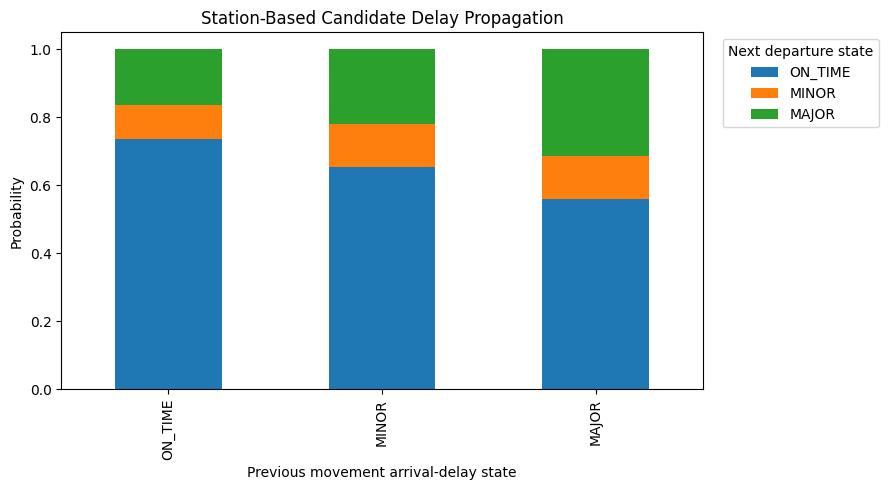

In [15]:
# Estimate P(current departure-delay state | previous arrival-delay state)
if len(candidate_pairs) < MIN_PROPAGATION_PAIRS:
    print(
        f"Only {len(candidate_pairs)} candidate pairs were found. "
        "Do not interpret the CPT yet; check time formats, station names, and the window."
    )
    propagation_model = None
    propagation_inference = None
    propagation_cpds = []
else:
    propagation_training_data = candidate_pairs[
        ["PREVIOUS_DELAY_STATE", "CURRENT_DELAY_STATE"]
    ].dropna().astype(str).copy()

    propagation_edges = [("PREVIOUS_DELAY_STATE", "CURRENT_DELAY_STATE")]
    propagation_model = DiscreteBayesianNetwork(propagation_edges)
    propagation_estimator = BayesianEstimator(
        propagation_model, propagation_training_data
    )
    propagation_cpds = propagation_estimator.get_parameters(
        prior_type="BDeu", equivalent_sample_size=10, n_jobs=1
    )
    propagation_model.add_cpds(*propagation_cpds)
    assert propagation_model.check_model()

    propagation_inference = VariableElimination(propagation_model)
    propagation_table = pd.crosstab(
        propagation_training_data["PREVIOUS_DELAY_STATE"],
        propagation_training_data["CURRENT_DELAY_STATE"],
        normalize="index"
    ).reindex(
        index=["ON_TIME", "MINOR", "MAJOR"],
        columns=["ON_TIME", "MINOR", "MAJOR"],
        fill_value=0
    )

    print("Observed conditional proportions (row-normalized):")
    display(propagation_table.round(3))
    print("Learned Bayesian Network CPT:")
    print(propagation_model.get_cpds("CURRENT_DELAY_STATE"))

    def predict_propagated_delay(previous_state):
        state = str(previous_state).upper().strip()
        allowed = {"ON_TIME", "MINOR", "MAJOR"}
        if state not in allowed:
            raise ValueError("previous_state must be ON_TIME, MINOR, or MAJOR")
        cpd = propagation_model.get_cpds("PREVIOUS_DELAY_STATE")
        if state not in cpd.state_names["PREVIOUS_DELAY_STATE"]:
            raise ValueError(f"State {state} was not observed in the propagation sample.")
        query = propagation_inference.query(
            variables=["CURRENT_DELAY_STATE"],
            evidence={"PREVIOUS_DELAY_STATE": state},
            show_progress=False
        )
        return pd.Series(
            query.values.flatten(),
            index=query.state_names["CURRENT_DELAY_STATE"],
            name=state
        ).reindex(["ON_TIME", "MINOR", "MAJOR"], fill_value=0.0)

    print("Estimated next-departure delay probabilities:")
    propagation_predictions = pd.DataFrame({
        state: predict_propagated_delay(state)
        for state in ["ON_TIME", "MINOR", "MAJOR"]
        if state in propagation_model.get_cpds("PREVIOUS_DELAY_STATE").state_names["PREVIOUS_DELAY_STATE"]
    }).T
    display((propagation_predictions * 100).round(2).rename_axis("Previous arrival state"))

    ax = propagation_predictions.plot(kind="bar", stacked=True, figsize=(9, 5))
    ax.set_xlabel("Previous movement arrival-delay state")
    ax.set_ylabel("Probability")
    ax.set_title("Station-Based Candidate Delay Propagation")
    ax.legend(title="Next departure state", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()


### How to interpret this result

For example, if the model estimates a higher probability of a major departure delay when the preceding candidate arrival is in the `MAJOR` state, this suggests an association in the sampled records. It does **not** prove that the first movement caused the next movement's delay. Confirmed operational dependencies would require data such as service turnarounds, platform assignments, track/block occupancy, or other railway dispatch records.

This first implementation matches movements on the same calendar date. It can miss overnight connections and depends on the timestamp format being parsed correctly.

In [16]:
# Save the propagation experiment outputs.
os.makedirs("railway_bn_results", exist_ok=True)
candidate_pairs.to_csv(
    "railway_bn_results/station_candidate_propagation_pairs.csv", index=False
)

if propagation_model is not None:
    joblib.dump({
        "model": propagation_model,
        "edges": propagation_edges,
        "time_window_minutes": PROPAGATION_WINDOW_MINUTES,
        "interpretation": (
            "Station/time candidate association; not verified physical-track dependency "
            "or proof of causation."
        )
    }, "railway_bn_results/station_propagation_bn.joblib")

print("Saved candidate pairs: railway_bn_results/station_candidate_propagation_pairs.csv")
if propagation_model is not None:
    print("Saved propagation model: railway_bn_results/station_propagation_bn.joblib")


Saved candidate pairs: railway_bn_results/station_candidate_propagation_pairs.csv
Saved propagation model: railway_bn_results/station_propagation_bn.joblib


## 12. Export the model and project artifacts

In [17]:
# Save model, metadata, and tables so the project is reproducible.
joblib.dump({
    "model": model,
    "edges": edges,
    "bn_columns": bn_columns,
    "evidence_columns": evidence_columns,
    "mean_delay_by_state": mean_delay_by_state,
    "class_labels": ["ON_TIME","MINOR","MAJOR"],
    "max_rows": MAX_ROWS,
    "random_state": RANDOM_STATE
}, "railway_bn_results/enhanced_railway_bn_model.joblib")

pd.DataFrame(edges, columns=["Parent","Child"]).to_csv(
    "railway_bn_results/enhanced_network_edges.csv", index=False
)
bn_data.to_csv("railway_bn_results/prepared_bn_data.csv", index=False)
pd.DataFrame({
    "DELAY_STATE": list(mean_delay_by_state.keys()),
    "MEAN_DELAY_MINUTES": list(mean_delay_by_state.values())
}).to_csv("railway_bn_results/mean_delay_by_state.csv", index=False)

print("Saved files in ./railway_bn_results/")
print("- enhanced_railway_bn_model.joblib")
print("- enhanced_network_edges.csv")
print("- prepared_bn_data.csv")
print("- mean_delay_by_state.csv")
print("- enhanced_bayesian_network.png (created in visualization cell)")

Saved files in ./railway_bn_results/
- enhanced_railway_bn_model.joblib
- enhanced_network_edges.csv
- prepared_bn_data.csv
- mean_delay_by_state.csv
- enhanced_bayesian_network.png (created in visualization cell)


## 13. How to present the improvements to your teacher

1. **Richer network:** the model has 11 nodes and multiple parent relationships rather than a small set of direct causes pointing to one target.
2. **Dataset-grounded variables:** calendar, source/destination station, distance, operator, scheduled time period, departure delay and a clearly defined historical traffic proxy.
3. **Probabilistic output:** shows posterior probabilities for `ON_TIME`, `MINOR`, and `MAJOR`, not only one label.
4. **Evaluation:** held-out test split, accuracy, balanced accuracy, per-class precision/recall/F1 and confusion matrix.
5. **Interpretability:** inspect CPTs and summarize recorded delay-cause columns separately.
6. **Reproducibility:** saves the trained model, prepared data, edge list and graph image.

**Limitations to state honestly:** the traffic node is a proxy; sampled records may omit trains; exact inference can be slow; and the proposed graph is a domain-informed structure rather than a causal discovery result. If the target delay column or column names differ, adjust the loading/target cell before running the rest.